# 🔎 4. EDA univariado, bivariado y multivariado

Este capítulo explora las variables candidatas y su relación con el objetivo, **solo con train** (1 jul – 2 sep). El componente temporal (autocorrelación, estacionariedad, deriva, festivos) se analiza en el capítulo 6.

```{note}
**Unidad de análisis para las pruebas.** Las filas de un mismo negocio no son independientes (cap. 1). Por eso las pruebas de hipótesis se hacen **a nivel de negocio**: primero se resume cada negocio y luego se compara entre negocios, con $n \approx 450$ y no $n \approx 28\,000$. Hacer las pruebas fila a fila daría p-valores artificialmente pequeños.
```

Para cada familia de pruebas se reporta el **tamaño del efecto** y los p-valores se corrigen por **comparaciones múltiples con Holm**, que controla la probabilidad de al menos un falso positivo en la familia y es menos conservador que Bonferroni.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

from comun import (estilo, cargar_panel, crear_variables, CORTE, AZUL, NARANJA, GRIS, PALETA, DIAS,
                   MEDIOS, VARIABLES_NUM, formato_p)

estilo()
SEED = 42
panel = cargar_panel()
train = panel[panel["fecha"] <= CORTE].copy()
train["y_log"] = np.log1p(train["venta_total"].clip(lower=0))
print(f"train: {len(train):,} filas, {train['negocio'].nunique()} negocios")

train: 28,469 filas, 448 negocios


## 📊 4.1 Univariado: medios de pago

La distribución del objetivo ya se analizó en el capítulo 3. Aquí se miran los medios de pago, que entrarán como rezagos: qué tan seguido se usan y cuánto pesan en la venta de cada negocio.

In [2]:
# [IA] resumen por medio: frecuencia de uso, monto típico y peso en el negocio
pm_cols = [f"pm_{m}" for m in MEDIOS] + ["pm_otros"]
filas = []
for c in pm_cols:
    v = train[c]
    usa = train.groupby("negocio")[c].sum() > 0
    part = (train.groupby("negocio")[c].sum() / train.groupby("negocio")["venta_total"].sum())[usa]
    filas.append({
        "medio": c.replace("pm_", ""),
        "% negocio-días > 0": (v > 0).mean() * 100,
        "negocios que lo usan": usa.sum(),
        "mediana cuando > 0 (miles COP)": v[v > 0].median() / 1e3,
        "asimetría log1p (> 0)": stats.skew(np.log1p(v[v > 0])),
        "participación mediana en su negocio (%)": part.median() * 100,
    })
uni = pd.DataFrame(filas).set_index("medio")
uni

,% negocio-días > 0,negocios que lo usan,mediana cuando > 0 (miles COP),asimetría log1p (> 0),participación mediana en su negocio (%)
medio,,,,,
efectivo,99.22,447,"3,422.53",-0.50,59.02
datafono,77.74,368,"2,529.89",-0.14,33.73
rumbo,32.08,144,"3,019.17",-0.22,6.75
mi_empresa,30.25,145,929.00,-0.06,2.03
credito_clientes,18.76,126,506.84,0.14,0.66
otros,63.57,316,271.17,-0.49,1.07


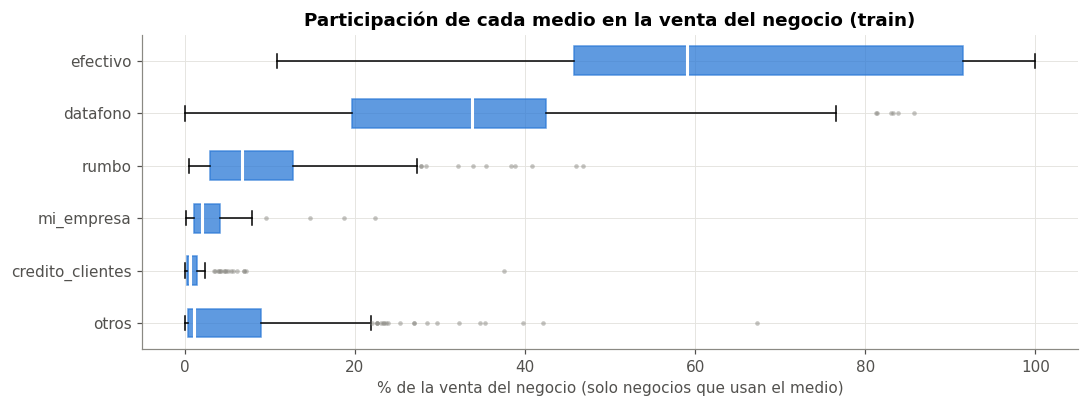

In [3]:
# participación de cada medio por negocio (solo negocios que lo usan)
part_neg = train.groupby("negocio")[pm_cols].sum().div(train.groupby("negocio")["venta_total"].sum(), axis=0)

fig, ax = plt.subplots(figsize=(10, 3.8))
datos = [part_neg.loc[part_neg[c] > 0, c].clip(0, 1) * 100 for c in pm_cols]
bp = ax.boxplot(datos, vert=False, labels=[c.replace("pm_", "") for c in pm_cols], patch_artist=True,
                widths=0.55, flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.5))
for b in bp["boxes"]:
    b.set(facecolor=AZUL, alpha=0.75, edgecolor=AZUL)
for m in bp["medians"]:
    m.set(color="white", linewidth=2)
ax.set_title("Participación de cada medio en la venta del negocio (train)")
ax.set_xlabel("% de la venta del negocio (solo negocios que usan el medio)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Interpretación

- **Efectivo** aparece en 447 de 448 negocios y en el 99 % de los negocio-días. Es la base de la venta (mediana del 59 % del negocio), con mucha dispersión: hay negocios donde es casi el 100 %.
- **Datáfono** lo usan 368 negocios y pesa típicamente un tercio de la venta.
- **Rumbo** y **Mi Empresa** (créditos corporativos) solo aparecen en unos 145 negocios, casi siempre los mismos, y con participaciones moderadas (medianas de 7 % y 2 %). En algunos negocios Rumbo llega a más del 40 %.
- **Crédito clientes** y **otros** pesan muy poco (medianas del 1 % o menos), aunque "otros" aparece en el 64 % de los negocio-días.
- En los negocios que los usan, los montos por medio en log1p son casi simétricos (asimetría entre −0,5 y 0,14).

**Decisión →** el **mix** de medios describe el tipo de negocio mejor que los montos por medio, que ya están contenidos en el total. Por eso los medios entran al modelo como **participación en los 7 días anteriores** (`part_*`), y no como montos, que serían casi colineales con los rezagos del total (ver 4.3).

## 🔗 4.2 Bivariado

### a) Venta vs. día de la semana

Para quitar el efecto de tamaño, a cada negocio se le resta su propia media en log. Así queda la **desviación relativa** de cada día de la semana respecto a lo normal para ese negocio. Como cada negocio aporta los 7 días, es un diseño de **medidas repetidas**: se usa la prueba de **Friedman** con la **W de Kendall** como tamaño del efecto. Después se hacen las 21 comparaciones por pares con **Wilcoxon pareado** y corrección de Holm.

In [4]:
# [IA] perfil semanal por negocio: media de log por día de semana menos la media del negocio
pos = train[train["venta_total"] > 0].copy()
pos["dia"] = pos["fecha"].dt.dayofweek
perfil = pos.groupby(["negocio", "dia"])["y_log"].mean().unstack()
perfil = perfil.dropna()  # solo negocios con los 7 días observados
perfil = perfil.sub(perfil.mean(axis=1), axis=0)

chi2, p_fr = stats.friedmanchisquare(*[perfil[d] for d in range(7)])
n_neg, k = perfil.shape
W = chi2 / (n_neg * (k - 1))
print(f"Friedman: chi2 = {chi2:,.1f}, p = {p_fr:.1e}, n = {n_neg} negocios, W de Kendall = {W:.3f}")

efecto = (np.expm1(perfil.median()) * 100).rename("mediana (% vs. la media del negocio)")
efecto.index = DIAS
efecto.to_frame().T

Friedman: chi2 = 738.7, p = 2.6e-156, n = 445 negocios, W de Kendall = 0.277


,lun,mar,mié,jue,vie,sáb,dom
mediana (% vs. la media del negocio),-9.36,-2.27,0.21,3.14,8.28,12.22,-7.78


In [5]:
# [IA] comparaciones por pares con Wilcoxon pareado + Holm; efecto = correlación biserial por rangos
pares = []
for i in range(7):
    for j in range(i + 1, 7):
        dif = perfil[i] - perfil[j]
        res = stats.wilcoxon(dif)
        rango = stats.rankdata(np.abs(dif))
        r_rb = (rango[dif > 0].sum() - rango[dif < 0].sum()) / rango.sum()
        pares.append((DIAS[i], DIAS[j], np.median(dif), r_rb, res.pvalue))
pares = pd.DataFrame(pares, columns=["día A", "día B", "dif. mediana (log)", "r biserial", "p"])
pares["p Holm"] = multipletests(pares["p"], method="holm")[1]
pares["significativo"] = pares["p Holm"] < 0.05
print(f"pares significativos tras Holm: {pares['significativo'].sum()} de {len(pares)}")
formato_p(pares.sort_values("r biserial", key=np.abs, ascending=False)).head(10)

pares significativos tras Holm: 19 de 21


,día A,día B,dif. mediana (log),r biserial,p,p Holm,significativo
4,lun,sáb,-0.21,-0.90,4.6e-61,9.7e-60,True
3,lun,vie,-0.17,-0.89,8.3e-60,1.7e-58,True
20,sáb,dom,0.20,0.77,1.9e-44,3.5e-43,True
2,lun,jue,-0.14,-0.73,1.3e-40,2.3e-39,True
8,mar,vie,-0.09,-0.68,6.6e-36,1.1e-34,True
7,mar,jue,-0.05,-0.68,7.7e-36,1.2e-34,True
9,mar,sáb,-0.13,-0.68,1.5e-35,2.3e-34,True
12,mié,vie,-0.06,-0.61,6.0e-29,8.4e-28,True
19,vie,dom,0.16,0.60,8.0e-28,1.0e-26,True
13,mié,sáb,-0.10,-0.59,3.2e-27,3.8e-26,True


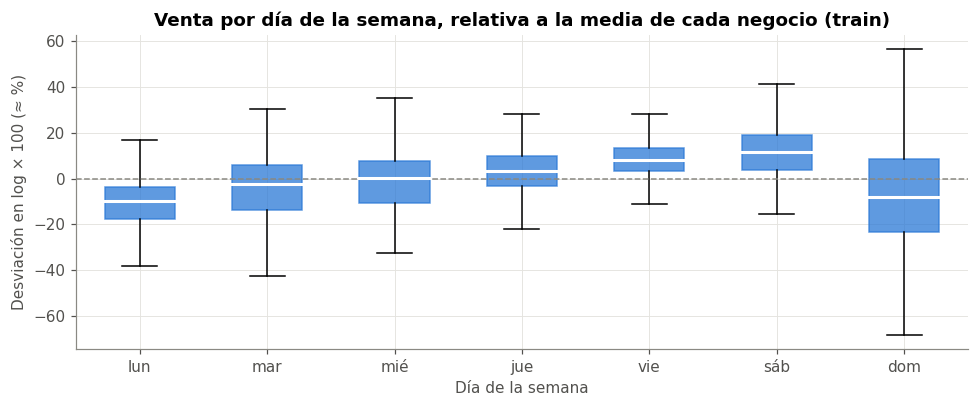

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bp = ax.boxplot([perfil[d] * 100 for d in range(7)], labels=DIAS, patch_artist=True, widths=0.55, showfliers=False)
for b in bp["boxes"]:
    b.set(facecolor=AZUL, alpha=0.75, edgecolor=AZUL)
for m in bp["medians"]:
    m.set(color="white", linewidth=2)
ax.axhline(0, color=GRIS, lw=1, ls="--")
ax.set_title("Venta por día de la semana, relativa a la media de cada negocio (train)")
ax.set_ylabel("Desviación en log × 100 (≈ %)")
ax.set_xlabel("Día de la semana")
plt.tight_layout()
plt.show()

### Interpretación

El patrón semanal es **claro**: la prueba de Friedman rechaza con mucha fuerza que todos los días sean iguales ($p \approx 10^{-156}$, 445 negocios). La **W de Kendall = 0,28** indica una concordancia **moderada**: la mayoría de negocios comparte el mismo orden de días, pero no todos (0 = ningún acuerdo, 1 = todos iguales).

- El **lunes** (−9 %) y el **domingo** (−8 %) son los días más bajos respecto a la media de cada negocio. El **sábado** (+12 %) y el **viernes** (+8 %) son los más altos.
- 19 de los 21 pares de días difieren después de Holm. Los efectos más grandes son lunes contra sábado y viernes ($r \approx 0{,}9$: en casi todos los negocios el sábado supera al lunes).
- La muestra del 16 al 24 sep sugería que el domingo era el día más bajo. Con todo train, el lunes y el domingo quedan prácticamente empatados.

**Decisión →** el **día de la semana** del día a pronosticar entra como variable categórica (one-hot), y se incluyen el **rezago de 7 días** y el ingenuo estacional como línea base (cap. 6 y 8).

### b) Venta vs. rezagos (relación dentro de cada negocio)

La correlación entre la venta de hoy y la de ayer, calculada con todas las filas juntas, sería altísima solo porque los negocios grandes venden mucho todos los días. Para medir la relación **dentro** de cada negocio, se calcula la correlación de Spearman negocio por negocio y se resume su distribución. La prueba es un Wilcoxon de una muestra sobre las correlaciones, con Holm entre las variables.

In [7]:
# [IA] Spearman dentro de cada negocio entre y_log y cada rezago/ventana
var = crear_variables(panel)
var_tr = var[(var["fecha"] <= CORTE) & var["lag14"].notna() & (var["venta_total"] > 0)]
candidatas = ["lag1", "lag7", "lag14", "media7", "std7", "nivel", "dias_sin_venta7"] + [f"part_{m}" for m in MEDIOS]

filas = []
for c in candidatas:
    rhos = var_tr.groupby("negocio").apply(
        lambda d: stats.spearmanr(d["y_log"], d[c]).correlation if d[c].nunique() > 1 else np.nan).dropna()
    filas.append((c, rhos.median(), rhos.quantile(0.25), rhos.quantile(0.75), len(rhos), stats.wilcoxon(rhos).pvalue))
corr_intra = pd.DataFrame(filas, columns=["variable", "rho mediana", "p25", "p75", "negocios", "p"]).set_index("variable")
corr_intra["p Holm"] = multipletests(corr_intra["p"], method="holm")[1]

# comparación: la misma correlación con todas las filas juntas
corr_intra["rho con filas juntas"] = [stats.spearmanr(var_tr["y_log"], var_tr[c], nan_policy="omit").correlation for c in candidatas]
formato_p(corr_intra.sort_values("rho mediana", ascending=False))

,rho mediana,p25,p75,negocios,p,p Holm,rho con filas juntas
variable,,,,,,,
lag7,0.36,0.20,0.49,447,1.5e-70,1.8e-69,0.98
lag14,0.29,0.15,0.44,447,2.8e-67,3.0e-66,0.97
lag1,0.24,0.11,0.36,447,6.3e-64,6.3e-63,0.98
media7,0.08,-0.03,0.20,447,8.0e-22,7.2e-21,0.98
part_mi_empresa,0.04,-0.08,0.14,145,2.5e-02,1.5e-01,0.78
part_efectivo,0.00,-0.11,0.11,386,9.7e-01,1.0e+00,-0.50
part_credito_clientes,-0.00,-0.11,0.13,124,9.7e-01,1.0e+00,0.68
part_rumbo,-0.01,-0.13,0.11,144,5.6e-01,1.0e+00,0.78
part_datafono,-0.01,-0.11,0.11,367,7.0e-01,1.0e+00,0.46


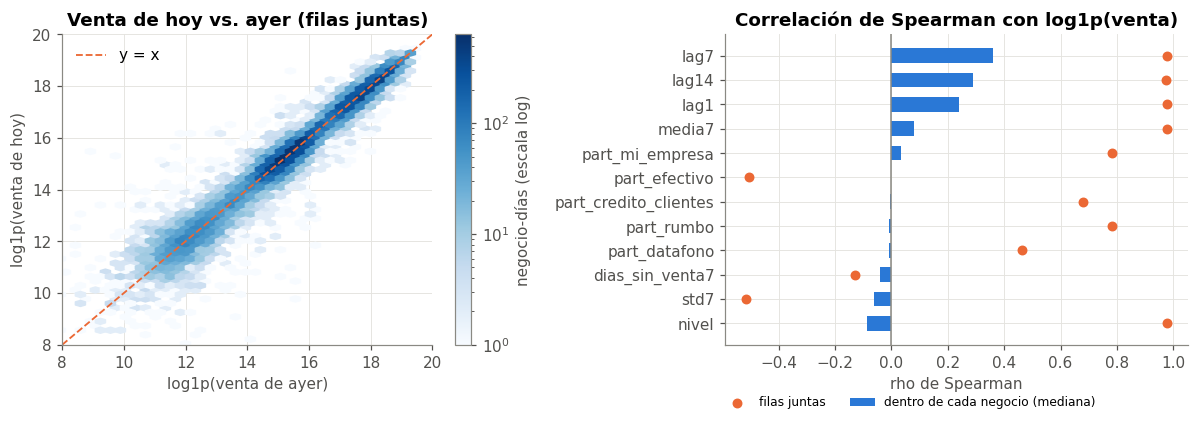

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
hb = ax.hexbin(var_tr["lag1"], var_tr["y_log"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
ax.plot([8, 20], [8, 20], color=NARANJA, lw=1.2, ls="--", label="y = x")
ax.set_xlim(8, 20); ax.set_ylim(8, 20)
ax.set_title("Venta de hoy vs. ayer (filas juntas)")
ax.set_xlabel("log1p(venta de ayer)")
ax.set_ylabel("log1p(venta de hoy)")
ax.legend(frameon=False, loc="upper left")
fig.colorbar(hb, ax=ax, label="negocio-días (escala log)")

ax = axes[1]
orden = corr_intra.sort_values("rho mediana").index
ax.barh(orden, corr_intra.loc[orden, "rho mediana"], color=AZUL, height=0.6, label="dentro de cada negocio (mediana)")
ax.scatter(corr_intra.loc[orden, "rho con filas juntas"], orden, color=NARANJA, s=30, zorder=3, label="filas juntas")
ax.axvline(0, color=GRIS, lw=1)
ax.set_title("Correlación de Spearman con log1p(venta)")
ax.set_xlabel("rho de Spearman")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

### Interpretación

- Con las filas juntas, casi cualquier variable de nivel (rezagos, media de 7 días, nivel histórico) tiene correlación cercana a 1: es la **diferencia de tamaño entre negocios**, no capacidad de pronóstico. Es el mismo efecto que inflará el R² en el capítulo 8.
- **Dentro** de cada negocio las correlaciones son modestas. La más fuerte es la del **rezago de 7 días** (mediana $\rho = 0{,}36$), seguida del rezago 14 (0,29) y del rezago 1 (0,24). Es coherente con el patrón semanal: el mismo día de la semana pasada se parece más a hoy que ayer.
- La **media de 7 días** casi no se relaciona dentro del negocio (0,08): al promediar la semana completa se borra el patrón semanal. El **nivel histórico** (media desde el inicio) tiene correlación ligeramente negativa: reacciona lento y queda desfasado en los negocios que cambian de nivel (cap. 6.4). Aun así, ambas variables sirven para ubicar al negocio en su escala.
- Las participaciones de los medios **no se relacionan** con la venta dentro del negocio (ninguna es significativa tras Holm), porque su mix cambia poco día a día. Pero sí distinguen negocios entre sí (siguiente prueba).

**Decisión →** se usan los rezagos 1, 7 y 14 (señal dentro del negocio), y la media, la desviación de 7 días y el nivel histórico (escala y volatilidad del negocio). El R² se reporta también **dentro de cada negocio** (cap. 8), porque el R² con las filas juntas engaña.

### c) Mix de medios vs. tamaño del negocio (entre negocios)

A nivel de negocio ($n \approx 450$): ¿los negocios grandes tienen un mix de medios distinto? Se usa Spearman entre la venta media (log) y la participación de cada medio, con Holm sobre las 6 pruebas.

In [9]:
tam = train.groupby("negocio")["y_log"].mean()
filas = []
for c in pm_cols:
    r = stats.spearmanr(tam, part_neg[c].clip(-1, 2))
    filas.append((c.replace("pm_", ""), r.correlation, r.pvalue))
mix = pd.DataFrame(filas, columns=["medio", "rho con tamaño", "p"]).set_index("medio")
mix["p Holm"] = multipletests(mix["p"], method="holm")[1]
mix["magnitud"] = pd.cut(mix["rho con tamaño"].abs(), [0, 0.1, 0.3, 0.5, 1], labels=["despreciable", "pequeña", "moderada", "grande"])
formato_p(mix)

,rho con tamaño,p,p Holm,magnitud
medio,,,,
efectivo,-0.50,2.8e-30,8.5e-30,grande
datafono,0.46,3.6e-25,7.1e-25,moderada
rumbo,0.79,4.5e-95,2.2e-94,grande
mi_empresa,0.79,1.3e-95,8.0e-95,grande
credito_clientes,0.72,4.5e-74,1.8e-73,grande
otros,0.14,4.2e-03,4.2e-03,pequeña


### Interpretación

El mix de medios está **muy asociado al tamaño** del negocio. Los negocios grandes, probablemente EDS, usan más los **créditos corporativos** (Rumbo y Mi Empresa, $\rho \approx 0{,}79$) y el crédito a clientes (0,72), y en los pequeños pesa más el **efectivo** ($\rho = -0{,}50$). Para la magnitud se usan los umbrales convencionales de Cohen para correlaciones (0,1 / 0,3 / 0,5).

**Decisión →** las participaciones `part_*` ayudan al modelo global a "reconocer" qué tipo de negocio está pronosticando, que es justo la variable que la base no trae (cap. 1).

## 🕸️ 4.3 Multivariado: redundancia entre variables candidatas

Un modelo lineal sufre cuando las variables son casi combinaciones lineales unas de otras: los coeficientes se vuelven inestables y difíciles de interpretar. Se revisa la matriz de correlaciones (Spearman) y el **factor de inflación de la varianza (VIF)** de las variables candidatas en train.

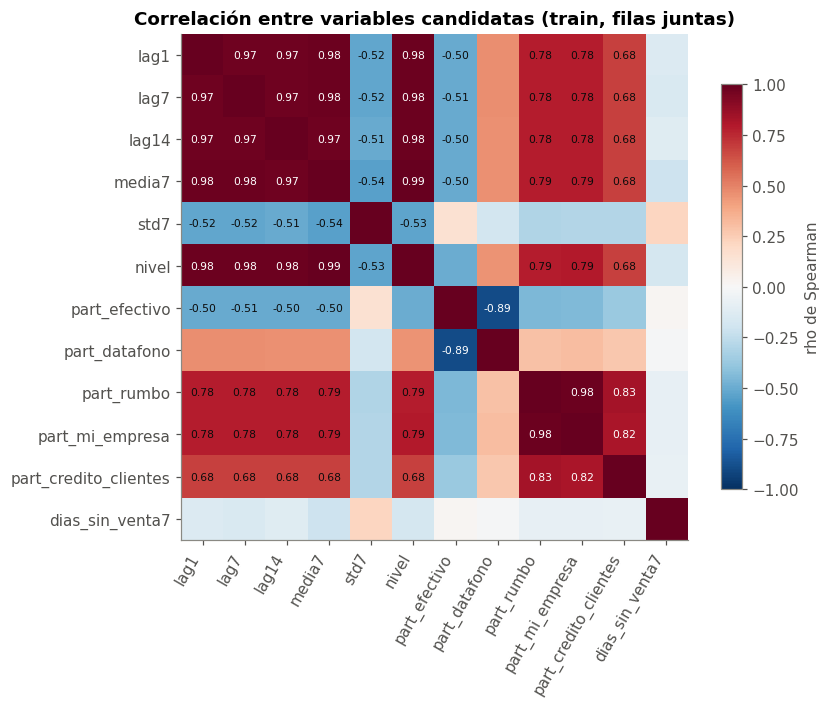

In [10]:
X = var_tr[VARIABLES_NUM].drop(columns="festivo").dropna()
corr = X.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iloc[i, j]) >= 0.5 and i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(corr.iloc[i, j]) > 0.8 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="rho de Spearman", shrink=0.8)
ax.set_title("Correlación entre variables candidatas (train, filas juntas)")
plt.tight_layout()
plt.show()

In [11]:
# [IA] VIF: cuánto se infla la varianza de cada coeficiente por la colinealidad
Xs = (X - X.mean()) / X.std()
Xs = Xs.assign(const=1.0)
vif = pd.Series([variance_inflation_factor(Xs.values, i) for i in range(Xs.shape[1] - 1)],
                index=X.columns, name="VIF").sort_values(ascending=False)
vif.to_frame().assign(alerta=lambda d: np.where(d["VIF"] > 10, "alta (> 10)", np.where(d["VIF"] > 5, "moderada (5-10)", "")))

,VIF,alerta
media7,54.00,alta (> 10)
nivel,37.55,alta (> 10)
part_efectivo,12.18,alta (> 10)
part_datafono,10.97,alta (> 10)
lag7,9.45,moderada (5-10)
lag1,9.34,moderada (5-10)
lag14,7.80,moderada (5-10)
dias_sin_venta7,4.52,
std7,4.48,
part_rumbo,3.74,


### Interpretación

Las variables de **nivel** (rezagos 1, 7 y 14, media de 7 días y nivel histórico) están muy correlacionadas entre sí y tienen VIF altos. Es esperable: todas miden "cuánto vende normalmente este negocio". Las participaciones de medios también se relacionan entre sí, porque suman casi 1.

**Decisiones →**

| Hallazgo | Decisión |
|---|---|
| Colinealidad fuerte entre variables de nivel | Se mantienen porque aportan información distinta dentro del negocio (4.2 b), pero se usa **regularización** (el parámetro $C$ del SVR, afinado con validación cruzada) y **estandarización** para que los coeficientes sean comparables |
| Coeficientes inestables con VIF alto | Los coeficientes del capítulo 8 se interpretan **por grupos** (nivel, semana, mix) y no uno por uno |
| `part_otros` es redundante (las participaciones suman ~1) | Se excluye y solo entran 5 participaciones |

## ✅ Resumen del capítulo

| # | Hallazgo | Evidencia | Decisión de modelado |
|---|---|---|---|
| 1 | Patrón semanal fuerte: lunes y domingo bajos, viernes y sábado altos (W = 0,28) | Friedman, W de Kendall, Wilcoxon + Holm | Día de la semana (one-hot) + rezago 7 + línea base estacional |
| 2 | La correlación con filas juntas la domina el tamaño del negocio | $\rho$ con filas juntas ≈ 1 vs. $\rho$ dentro del negocio moderado | Reportar el R² dentro del negocio. Sospechar de R² altos |
| 3 | Dentro del negocio, el rezago 7 es el mejor predictor (ρ = 0,36), por encima del rezago 1 | Spearman dentro de cada negocio + Holm | Rezagos 1, 7, 14 + media, desviación de 7 días y nivel |
| 4 | El mix de medios distingue tipos de negocio | Spearman con el tamaño + Holm | Participaciones `part_*` de los 7 días previos |
| 5 | Colinealidad alta entre variables de nivel | VIF | Estandarizar + regularizar ($C$) + interpretar por grupos |